# Data Visualisation and Exploration
## Assignment 2
##### Student no.: 2684883
##### Student no.: 2440810 

In [2]:
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import hdbscan
import umap
import seaborn as sns
import pandas as pd
import numpy as np

data = pd.read_csv('train.csv')

#### Initial Descriptive Statistics

In [3]:
print("Dataset shape:", data.shape)

display(data.head())

print("\nColumn information:")
data.info()

print("\nMissing values:")
print(data.isnull().sum())

print("\nNumerical summary:")
display(data.describe())

Dataset shape: (1458644, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 122.4 MB

Missing values:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude 

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
std,4.987772e-01,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03
min,1.000000e+00,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06


#### 2. Feature Engineering

In [9]:
def haversine_np(lon1, lat1, lon2, lat2):

    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6367 * c
    return km

data["trip_distance_km"] = haversine_np(
    data["pickup_latitude"],
    data["pickup_longitude"],
    data["dropoff_latitude"],
    data["dropoff_longitude"]
)

data["average_speed_kmh"] = (
    data["trip_distance_km"] /
    (data["trip_duration"] / 3600)
)

data["pickup_datetime"] = pd.to_datetime(data["pickup_datetime"])

data["pickup_day_of_week"] = (
    data["pickup_datetime"].dt.day_name()
)

data["pickup_day_number"] = (
    data["pickup_datetime"].dt.dayofweek
)



### Data Cleaning

In [10]:

print(data["trip_duration"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
))

print(data["average_speed_kmh"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
))

print(data["trip_distance_km"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
))

print("Trips <= 10 seconds:",
      (data["trip_duration"] <= 10).sum())

print("Trips > 2 hours:",
      (data["trip_duration"] > 7200).sum())

print("Trips > 4 hours:",
      (data["trip_duration"] > 14400).sum())

print("Trips > 24 hours:",
      (data["trip_duration"] > 86400).sum())

print(data["passenger_count"].value_counts().sort_index())

print("Zero-distance trips:",
      (data["trip_distance_km"] == 0).sum())

print("Trips > 100 km:",
      (data["trip_distance_km"] > 100).sum())

print("Trips > 100 km/h:",
      (data["average_speed_kmh"] > 100).sum())

print("Trips > 150 km/h:",
      (data["average_speed_kmh"] > 150).sum())

print("Trips > 200 km/h:",
      (data["average_speed_kmh"] > 200).sum())


count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
90%      1.634000e+03
95%      2.104000e+03
99%      3.440000e+03
99.9%    8.512836e+04
max      3.526282e+06
Name: trip_duration, dtype: float64
count    1.458644e+06
mean     1.138700e+01
std      1.362834e+01
min      0.000000e+00
90%      2.113236e+01
95%      2.696215e+01
99%      4.093905e+01
99.9%    5.682471e+01
max      8.613719e+03
Name: average_speed_kmh, dtype: float64
count    1.458644e+06
mean     2.874291e+00
std      4.432502e+00
min      0.000000e+00
90%      5.757097e+00
95%      1.227696e+01
99%      2.253290e+01
99.9%    2.580375e+01
max      8.514335e+02
Name: trip_distance_km, dtype: float64
Trips <= 10 seconds: 2166
Trips > 2 hours: 2253
Trips > 4 hours: 2077
Trips > 24 hours: 4
passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64
Zero-distance trips: 5897
Tri

In [11]:
# Examine the 10 longest trips
display(
    data.nlargest(10, "trip_duration")[
        [
            "trip_duration",
            "trip_distance_km",
            "average_speed_kmh",
            "pickup_latitude",
            "pickup_longitude",
            "dropoff_latitude",
            "dropoff_longitude"
        ]
    ]
)

# Examine the 10 longest-distance trips
display(
    data.nlargest(10, "trip_distance_km")[
        [
            "trip_duration",
            "trip_distance_km",
            "average_speed_kmh",
            "pickup_latitude",
            "pickup_longitude",
            "dropoff_latitude",
            "dropoff_longitude"
        ]
    ]
)

,trip_duration,trip_distance_km,average_speed_kmh,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude
978383,3526282,21.825119,0.022281,40.648632,-73.783905,40.750202,-73.978271
924150,2227612,0.487278,0.000787,40.742325,-73.983788,40.727676,-73.985489
680594,2049578,7.049941,0.012383,40.735252,-73.921677,40.759979,-73.984749
355003,1939736,19.001053,0.035264,40.643559,-73.789650,40.773087,-73.956810
1234291,86392,22.104214,0.921094,40.644825,-73.794525,40.755573,-73.991051
295382,86391,23.755867,0.989931,40.644688,-73.781952,40.745926,-73.993874
73816,86390,1.926475,0.080279,40.753220,-73.996010,40.740601,-73.979027
59891,86387,3.658383,0.152456,40.749729,-73.992279,40.800770,-73.962524
1360439,86385,22.560475,0.940183,40.644806,-73.782089,40.666828,-73.985016
753765,86379,5.810679,0.242170,40.734680,-74.006111,40.815449,-73.958809


,trip_duration,trip_distance_km,average_speed_kmh,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude
974378,611,851.433538,5016.629684,35.081532,-71.799896,40.436329,-79.352837
397526,2515,662.397499,948.163418,40.773598,-73.870682,38.963852,-79.817978
923793,1405,624.435418,1599.976871,40.758633,-73.972366,43.674000,-79.553535
1100676,3267,619.277693,682.399662,40.750023,-73.991325,43.921028,-79.518616
1013474,933,595.845649,2299.082892,40.756763,-73.978912,41.427902,-79.338699
910072,303,430.961663,5120.336588,40.756634,-73.989914,36.398121,-70.346077
184925,792,376.161495,1709.824977,51.881084,-72.809669,40.750599,-73.987228
377068,282,332.147389,4240.179432,40.717113,-74.007095,38.946033,-76.963242
1301396,9922,239.866877,87.030917,40.773251,-73.981491,40.243626,-76.135719
1060807,1131,236.226954,751.916032,44.371944,-66.972160,43.147583,-69.048019


In [12]:
# checking if the given duration matches the calculated duration from timestamps
data["pickup_datetime"] = pd.to_datetime(data["pickup_datetime"])
data["dropoff_datetime"] = pd.to_datetime(data["dropoff_datetime"])

data["calculated_duration"] = (
    data["dropoff_datetime"] - data["pickup_datetime"]
).dt.total_seconds()

print("Duration mismatches:",
      (data["calculated_duration"] != data["trip_duration"]).sum())

print("Negative timestamp durations:",
      (data["calculated_duration"] < 0).sum())

Duration mismatches: 0
Negative timestamp durations: 0


In [13]:
# Investigate unusually long trip durations

long_trips = data[data["trip_duration"] > 14400]

print("Trips longer than 4 hours:", len(long_trips))

print("\nDuration distribution (hours):")
print((long_trips["trip_duration"] / 3600).describe())

print("\nTrips between 23 and 24 hours:")
print(
    data["trip_duration"].between(
        23 * 3600, 24 * 3600
    ).sum()
)

print("\nTrips between 4 and 23 hours:")
print(
    data["trip_duration"].between(
        4 * 3600, 23 * 3600,
        inclusive="left"
    ).sum()
)

Trips longer than 4 hours: 2077

Duration distribution (hours):
count    2077.000000
mean       24.113040
std        29.895757
min         4.282778
25%        23.548333
50%        23.847778
75%        23.948333
max       979.522778
Name: trip_duration, dtype: float64

Trips between 23 and 24 hours:
1839

Trips between 4 and 23 hours:
234


In [14]:
# Investigate trips near 24 hours
near_24h = data[
    (data["trip_duration"] >= 23 * 3600) &
    (data["trip_duration"] < 24 * 3600)
]

print("Trips near 24 hours:", len(near_24h))

print("\nDistance statistics:")
print(near_24h["trip_distance_km"].describe())

print("\nAverage speed statistics:")
print(near_24h["average_speed_kmh"].describe())

print("\nExample trips:")
display(
    near_24h[
        ["trip_duration", "trip_distance_km", "average_speed_kmh"]
    ].head(10)
)

Trips near 24 hours: 1839

Distance statistics:
count    1839.000000
mean        3.137449
std         4.523589
min         0.000000
25%         0.906727
50%         1.612692
75%         3.218859
max        36.804429
Name: trip_distance_km, dtype: float64

Average speed statistics:
count    1839.000000
mean        0.132247
std         0.191304
min         0.000000
25%         0.038040
50%         0.068016
75%         0.135059
max         1.556908
Name: average_speed_kmh, dtype: float64

Example trips:


,trip_duration,trip_distance_km,average_speed_kmh
531,84594,0.848237,0.036098
1134,86149,1.551506,0.064834
1865,86352,3.079310,0.128376
3442,86236,1.300207,0.054278
4172,85197,1.914304,0.080889
4336,83016,0.499007,0.021640
5104,85946,0.960268,0.040223
5778,84070,1.666412,0.071358
6132,84392,0.869661,0.037098
6513,86357,0.845380,0.035242


In [15]:
# Create cleaned dataset 
df_clean = data.copy()

valid_trips = (
    (df_clean["trip_duration"] > 10) &
    (df_clean["trip_duration"] <= 14400) &
    (df_clean["passenger_count"].between(1, 6)) &
    (df_clean["trip_distance_km"] > 0) &
    (df_clean["average_speed_kmh"] > 0) &
    (df_clean["average_speed_kmh"] <= 100)
)

df_clean = df_clean.loc[valid_trips].copy()

original_rows = len(data)
cleaned_rows = len(df_clean)
removed_rows = original_rows - cleaned_rows

print("Original records:", original_rows)
print("Cleaned records:", cleaned_rows)
print("Records removed:", removed_rows)
print("Percentage removed:",
      round(removed_rows / original_rows * 100, 3), "%")

print("\nRemaining trips exceeding 100 km:",
      (df_clean["trip_distance_km"] > 100).sum())

Original records: 1458644
Cleaned records: 1449074
Records removed: 9570
Percentage removed: 0.656 %

Remaining trips exceeding 100 km: 6


In [16]:
# Check coordinates outside a broad NYC regional boundary

pickup_outside = ~(
    df_clean["pickup_latitude"].between(40.3, 41.1) &
    df_clean["pickup_longitude"].between(-74.5, -73.3)
)

dropoff_outside = ~(
    df_clean["dropoff_latitude"].between(40.3, 41.1) &
    df_clean["dropoff_longitude"].between(-74.5, -73.3)
)

outside_region = pickup_outside | dropoff_outside
both_outside = pickup_outside & dropoff_outside

print("Pickups outside region:", pickup_outside.sum())
print("Dropoffs outside region:", dropoff_outside.sum())
print("Trips with either location outside:", outside_region.sum())
print("Trips with both locations outside:", both_outside.sum())

display(
    df_clean.loc[outside_region, [
        "pickup_latitude",
        "pickup_longitude",
        "dropoff_latitude",
        "dropoff_longitude",
        "trip_distance_km",
        "trip_duration",
        "average_speed_kmh"
    ]].head(20)
)
display(
    df_clean.loc[both_outside, [
        "pickup_latitude",
        "pickup_longitude",
        "dropoff_latitude",
        "dropoff_longitude",
        "trip_distance_km",
        "trip_duration",
        "average_speed_kmh"
    ]].head(20)
)

Pickups outside region: 23
Dropoffs outside region: 83
Trips with either location outside: 86
Trips with both locations outside: 20


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,trip_distance_km,trip_duration,average_speed_kmh
14502,40.644718,-73.781792,41.311520,-72.711395,120.848510,7153,60.821283
73414,41.319164,-74.126724,40.829666,-73.935120,26.025018,3190,29.369926
81841,40.645061,-73.798218,40.629269,-74.562355,84.916188,4535,67.408661
85764,40.641670,-73.787064,40.809486,-73.193268,66.198028,3281,72.634227
108729,40.769417,-73.863182,41.181141,-73.849640,12.810059,2737,16.849182
112247,40.643410,-73.789871,41.334740,-73.684250,24.507458,5278,16.715962
136925,40.749851,-73.990723,41.143021,-73.258476,82.297553,4715,62.835883
149738,40.225803,-74.075287,40.225800,-74.075172,0.012718,147,0.311456
186174,41.157372,-73.774055,41.071087,-73.705620,8.064902,1056,27.493983
189789,40.774067,-73.872871,41.197395,-73.725464,20.990235,4750,15.908388


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,trip_distance_km,trip_duration,average_speed_kmh
149738,40.225803,-74.075287,40.225800,-74.075172,0.012718,147,0.311456
323254,40.436295,-74.521576,40.436321,-74.521576,0.000792,60,0.047515
497890,41.297848,-72.926605,41.297840,-72.926605,0.000249,25,0.035844
520715,41.211159,-73.802948,41.211163,-73.802948,0.000118,51,0.008347
634458,41.194454,-73.853012,41.194458,-73.853012,0.000118,58,0.007317
646911,41.256882,-73.686943,41.256889,-73.686920,0.002555,62,0.148330
663084,40.355713,-74.612442,40.355610,-74.612503,0.007431,105,0.254792
680379,41.120682,-73.706223,41.120789,-73.706367,0.016449,47,1.259934
771766,41.221169,-73.248062,41.221191,-73.248070,0.001121,28,0.144105
775976,35.310307,-72.074333,35.173546,-72.022408,7.432122,317,84.402648


### Question 3
#### 3.1

The most popular day of the week for pickups is: Friday


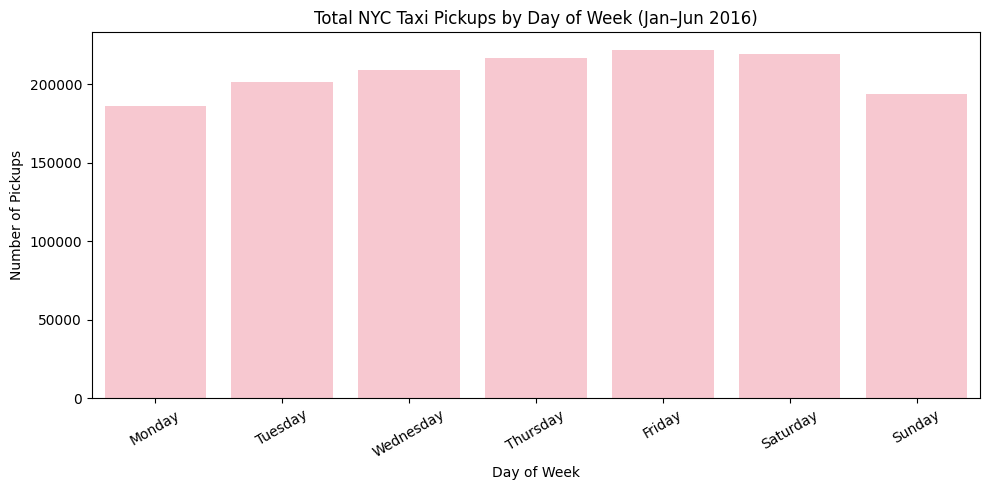

In [17]:
day_counts = (df_clean["pickup_day_of_week"].value_counts().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))
print("The most popular day of the week for pickups is:", day_counts.idxmax())

# The plot
plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_counts.index,
    y=day_counts.values,
    color="pink"
)
plt.title("Total NYC Taxi Pickups by Day of Week (Jan–Jun 2016)")
plt.xlabel("Day of Week")
plt.ylabel("Number of Pickups")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### 3.2

In [18]:
df_clean["pickup_hour"] = df_clean["pickup_datetime"].dt.hour

hourly_counts = (df_clean.groupby(["pickup_day_of_week", "pickup_hour"]).size().unstack(fill_value=0).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))

peak_hours = hourly_counts.idxmax(axis=1)
peak_hours_count = hourly_counts.max(axis=1)

results = pd.DataFrame({
    "Most Popular Hour": peak_hours,
    "Pickups": peak_hours_count
}) 

display(results)


,Most Popular Hour,Pickups
pickup_day_of_week,,
Monday,18,12876
Tuesday,18,13397
Wednesday,19,13626
Thursday,21,14072
Friday,19,14075
Saturday,23,13094
Sunday,0,12186


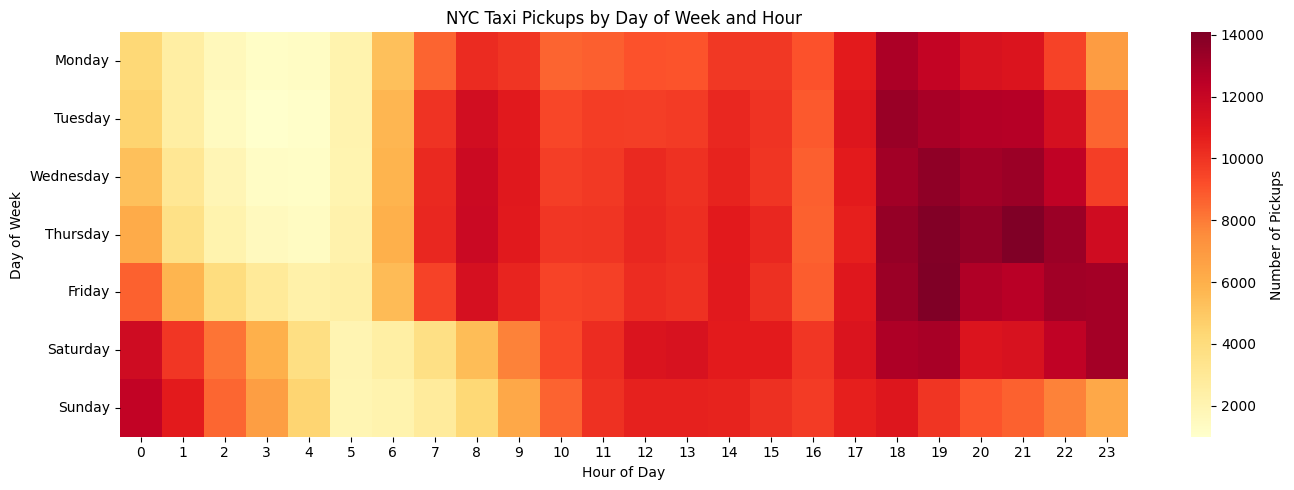

In [19]:
# The plot
plt.figure(figsize=(14, 5))

sns.heatmap(
    hourly_counts,
    cmap="YlOrRd",
    annot=False,
    cbar_kws={"label": "Number of Pickups"}
)

plt.title("NYC Taxi Pickups by Day of Week and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()


#### 3.3

day_type
Weekday    1035697
Weekend     413377
Name: count, dtype: int64


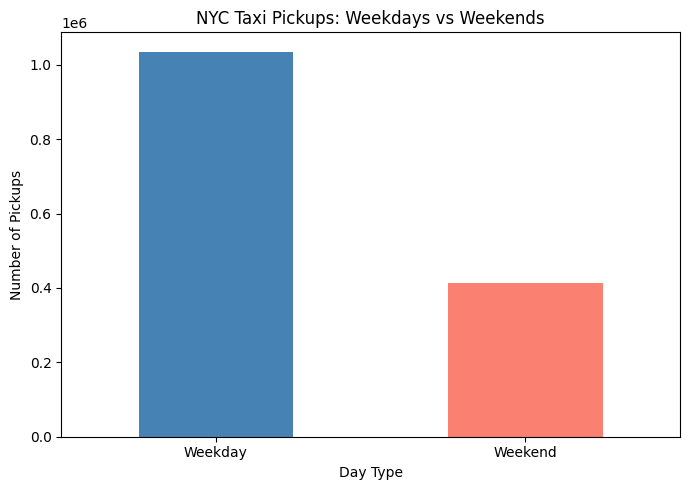

In [20]:

df_clean["day_type"] = df_clean["pickup_day_number"].apply(
    lambda x: "Weekday" if x < 5 else "Weekend"
)

# Count trips
day_type_counts = df_clean["day_type"].value_counts()

print(day_type_counts)


# The plot
plt.figure(figsize=(7, 5))

day_type_counts.reindex(["Weekday", "Weekend"]).plot(
    kind="bar",
    color=["steelblue", "salmon"]
)

plt.title("NYC Taxi Pickups: Weekdays vs Weekends")
plt.xlabel("Day Type")
plt.ylabel("Number of Pickups")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 3.4

MLK Day              7091
Valentine's Day      8426
St. Patrick's Day    8203
Easter Sunday        7314
Memorial Day         5535
dtype: int64

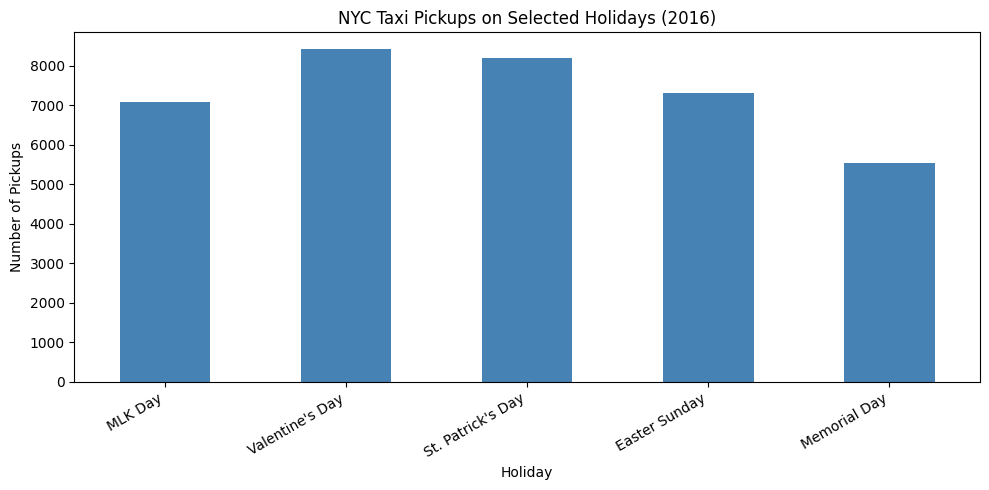

In [21]:
df_clean["pickup_datetime"] = pd.to_datetime(df_clean["pickup_datetime"])

df_clean["pickup_date"] = df_clean["pickup_datetime"].dt.normalize()
holidays = {
    "MLK Day": "2016-01-18",
    "Valentine's Day": "2016-02-14",
    "St. Patrick's Day": "2016-03-17",
    "Easter Sunday": "2016-03-27",
    "Memorial Day": "2016-05-30"
}

holiday_counts = {}

for holiday, date in holidays.items():
    holiday_counts[holiday] = (
        df_clean["pickup_date"] == pd.Timestamp(date)
    ).sum()

holiday_counts = pd.Series(holiday_counts)

display(holiday_counts)

# Graph plot
plt.figure(figsize=(10, 5))

holiday_counts.plot(kind="bar", color="steelblue")

plt.title("NYC Taxi Pickups on Selected Holidays (2016)")
plt.xlabel("Holiday")
plt.ylabel("Number of Pickups")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#### 3.5

pickup_hour
0     13.75
1     14.24
2     14.50
3     15.64
4     18.35
5     21.15
6     16.97
7     12.58
8     10.33
9     10.08
10    10.21
11     9.93
12     9.77
13     9.98
14     9.83
15     9.73
16    10.07
17     9.90
18     9.81
19    10.57
20    11.82
21    12.21
22    12.36
23    13.15
Name: average_speed_kmh, dtype: float64

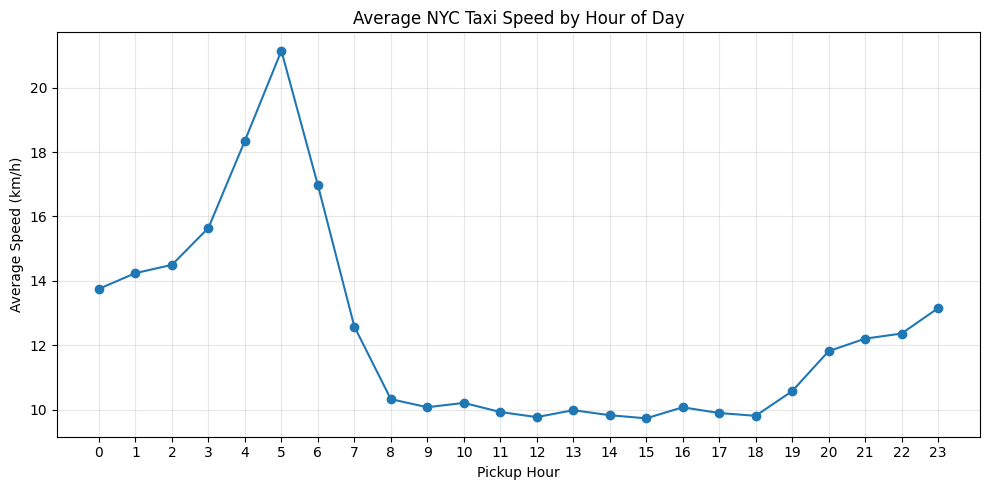

In [22]:
hourly_speed = (
    df_clean.groupby("pickup_hour")["average_speed_kmh"]
    .mean()
)

display(hourly_speed.round(2))

# Graph plot
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_speed.index,
    hourly_speed.values,
    marker="o"
)

plt.title("Average NYC Taxi Speed by Hour of Day")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Speed (km/h)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Question 4
#### 4.1

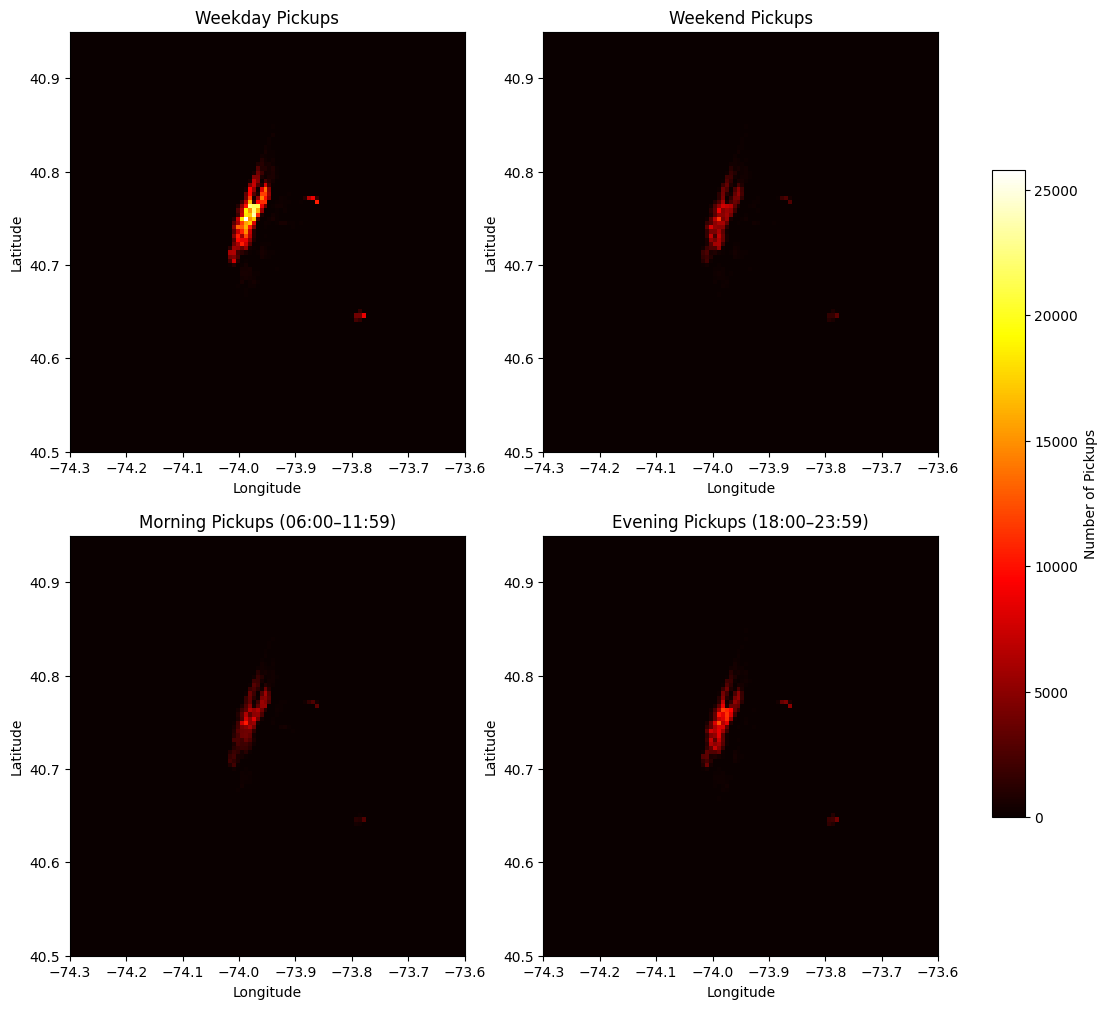

In [23]:

weekday_trips = df_clean[df_clean["pickup_day_number"] < 5]
weekend_trips = df_clean[df_clean["pickup_day_number"] >= 5]

morning_trips = df_clean[
    df_clean["pickup_hour"].between(6, 11)
]

evening_trips = df_clean[
    df_clean["pickup_hour"].between(18, 23)
]

lon_range = (-74.3, -73.6)
lat_range = (40.5, 40.95)

datasets = [
    ("Weekday Pickups", weekday_trips),
    ("Weekend Pickups", weekend_trips),
    ("Morning Pickups (06:00–11:59)", morning_trips),
    ("Evening Pickups (18:00–23:59)", evening_trips)
]

# The plot

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
max_count = 0
heatmaps = []

for title, data in datasets:
    counts, _, _ = np.histogram2d(
        data["pickup_longitude"],
        data["pickup_latitude"],
        bins=100,
        range=[lon_range, lat_range]
    )
    heatmaps.append(counts)
    max_count = max(max_count, counts.max())

for ax, (title, data), counts in zip(
    axes.flat, datasets, heatmaps
):
    image = ax.imshow(
        counts.T,
        origin="lower",
        extent=[
            lon_range[0], lon_range[1],
            lat_range[0], lat_range[1]
        ],
        cmap="hot",
        vmin=0,
        vmax=max_count,
        aspect="auto"
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label="Number of Pickups",
    shrink=0.7
)

plt.show()

#### 4.2

In [24]:
# Friday night: Friday 23:00 through Saturday 01:59
friday_night = df_clean[
    ((df_clean["pickup_day_number"] == 4) &
     (df_clean["pickup_hour"] == 23)) |
    ((df_clean["pickup_day_number"] == 5) &
     (df_clean["pickup_hour"].between(0, 1)))
].copy()

# Thursday evening: 17:00 through 19:59
thursday_evening = df_clean[
    (df_clean["pickup_day_number"] == 3) &
    (df_clean["pickup_hour"].between(17, 19))
].copy()

print("Friday night trips:", len(friday_night))
print("Thursday evening trips:", len(thursday_evening))

Friday night trips: 34686
Thursday evening trips: 38057


In [25]:
# Function to run DBSCAN clustering on pickup coordinates
EARTH_RADIUS_KM = 6371.0088

def run_dbscan(data, eps_km=0.2, min_samples=30):
    coordinates = data[
        ["pickup_latitude", "pickup_longitude"]
    ].to_numpy()

    coordinates_rad = np.radians(coordinates)

    model = DBSCAN(
        eps=eps_km / EARTH_RADIUS_KM,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    result = data.copy()
    result["cluster"] = model.fit_predict(coordinates_rad)

    return result


friday_clusters = run_dbscan(friday_night)
thursday_clusters = run_dbscan(thursday_evening)

def cluster_summary(data, name):
    labels = data["cluster"]

    n_clusters = labels[labels != -1].nunique()
    noise_count = (labels == -1).sum()

    print(f"\n{name}")
    print("Number of clusters:", n_clusters)
    print("Noise points:", noise_count)
    print("Noise percentage:",
          round(noise_count / len(data) * 100, 2), "%")

    print("\nLargest clusters:")
    print(
        labels[labels != -1]
        .value_counts()
        .head(10)
    )


cluster_summary(friday_clusters, "Friday Night")
cluster_summary(thursday_clusters, "Thursday Evening")


Friday Night
Number of clusters: 9
Noise points: 2319
Noise percentage: 6.69 %

Largest clusters:
cluster
0    30772
2      384
1      361
5      334
4      189
3      164
7       86
8       50
6       27
Name: count, dtype: int64

Thursday Evening
Number of clusters: 9
Noise points: 1206
Noise percentage: 3.17 %

Largest clusters:
cluster
0    34822
2      560
3      545
1      367
4      362
5       70
6       63
7       32
8       30
Name: count, dtype: int64


In [26]:
# Function to compare DBSCAN results for different eps values
def compare_eps(data, name):
    results = []

    for eps_km in [0.05, 0.10, 0.15, 0.20]:
        clustered = run_dbscan(
            data,
            eps_km=eps_km,
            min_samples=30
        )

        labels = clustered["cluster"]
        non_noise = labels[labels != -1]

        n_clusters = non_noise.nunique()
        largest_cluster = (
            non_noise.value_counts().max()
            if len(non_noise) > 0 else 0
        )

        results.append({
            "Period": name,
            "eps (metres)": int(eps_km * 1000),
            "Clusters": n_clusters,
            "Largest cluster": largest_cluster,
            "Largest cluster (%)": round(
                largest_cluster / len(data) * 100, 2
            ),
            "Noise (%)": round(
                (labels == -1).mean() * 100, 2
            )
        })

    return pd.DataFrame(results)


comparison = pd.concat([
    compare_eps(friday_night, "Friday Night"),
    compare_eps(thursday_evening, "Thursday Evening")
], ignore_index=True)

display(comparison)

,Period,eps (metres),Clusters,Largest cluster,Largest cluster (%),Noise (%)
0,Friday Night,50,142,1577,4.55,41.82
1,Friday Night,100,47,24060,69.37,15.79
2,Friday Night,150,20,28199,81.30,9.04
3,Friday Night,200,9,30772,88.72,6.69
4,Thursday Evening,50,181,1684,4.42,43.67
5,Thursday Evening,100,49,28108,73.86,8.02
6,Thursday Evening,150,10,34444,90.51,4.29
7,Thursday Evening,200,9,34822,91.50,3.17


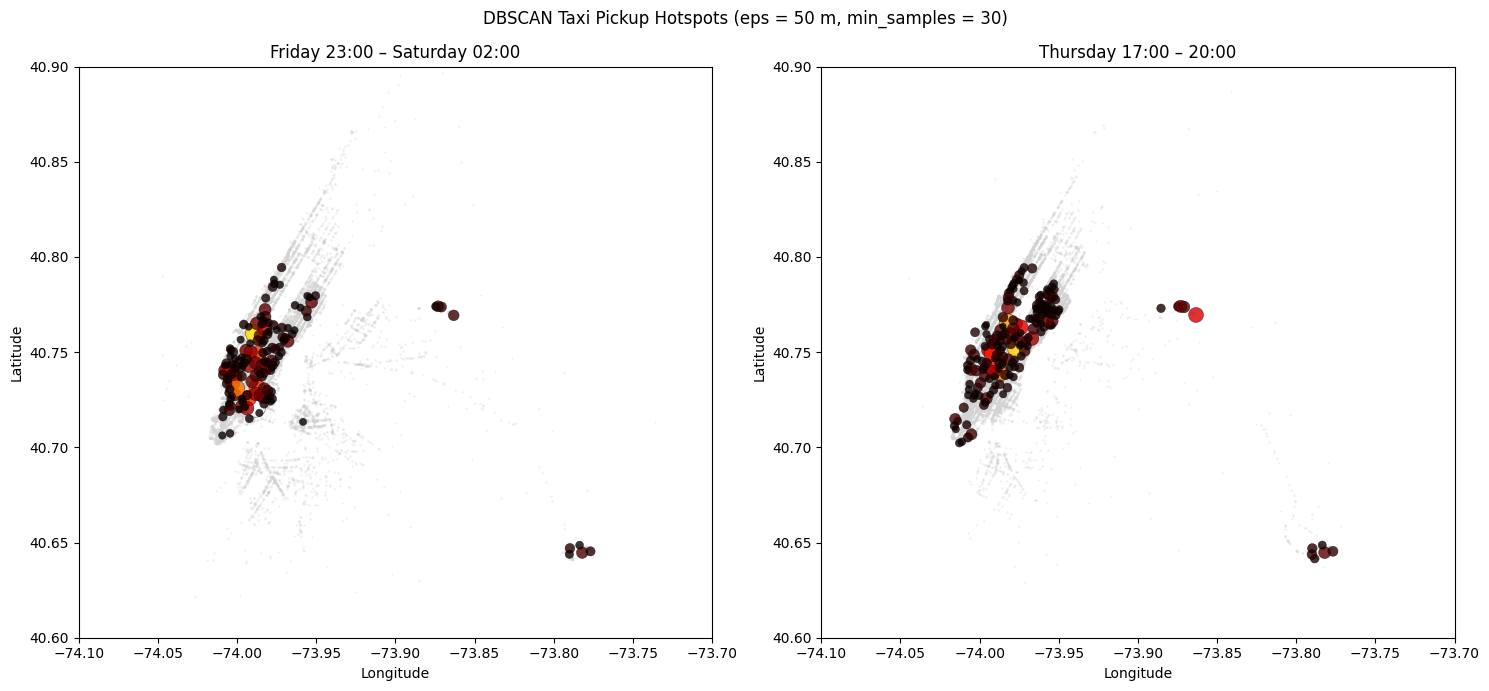

In [27]:
# Final DBSCAN parameters
friday_clusters = run_dbscan(
    friday_night,
    eps_km=0.05,
    min_samples=30
)

thursday_clusters = run_dbscan(
    thursday_evening,
    eps_km=0.05,
    min_samples=30
)


# The graph plot
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

datasets = [
    ("Friday 23:00 – Saturday 02:00", friday_clusters),
    ("Thursday 17:00 – 20:00", thursday_clusters)
]

for ax, (title, data) in zip(axes, datasets):

    # Plot noise in light grey
    noise = data[data["cluster"] == -1]

    ax.scatter(
        noise["pickup_longitude"],
        noise["pickup_latitude"],
        c="lightgrey",
        s=1,
        alpha=0.2
    )

    # Plot cluster centres, sized by number of pickups
    centres = (
        data[data["cluster"] != -1]
        .groupby("cluster")
        .agg(
            latitude=("pickup_latitude", "mean"),
            longitude=("pickup_longitude", "mean"),
            count=("cluster", "size")
        )
    )

    ax.scatter(
        centres["longitude"],
        centres["latitude"],
        s=np.sqrt(centres["count"]) * 5,
        c=centres["count"],
        cmap="hot",
        alpha=0.8,
        edgecolors="black",
        linewidths=0.3
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.set_xlim(-74.1, -73.7)
    ax.set_ylim(40.6, 40.9)

plt.suptitle("DBSCAN Taxi Pickup Hotspots (eps = 50 m, min_samples = 30)")
plt.tight_layout()
plt.show()

### Question 5

In [28]:
# Airport trips: Empire State Building → JFK and Empire State Building → Newark
empire_state = (40.756724, -73.983806)
jfk = (40.647929, -73.777813)
newark = (40.689442, -74.173242)

# Pickup distance from Empire State Building
pickup_distance = haversine_np(
    df_clean["pickup_latitude"],
    df_clean["pickup_longitude"],
    *empire_state
)

# Dropoff distance from JFK
jfk_distance = haversine_np(
    df_clean["dropoff_latitude"],
    df_clean["dropoff_longitude"],
    *jfk
)

# Dropoff distance from Newark
newark_distance = haversine_np(
    df_clean["dropoff_latitude"],
    df_clean["dropoff_longitude"],
    *newark
)

empire_pickups = pickup_distance <= 1.0

jfk_trips = df_clean[
    empire_pickups & (jfk_distance <= 2.0)
].copy()

newark_trips = df_clean[
    empire_pickups & (newark_distance <= 2.0)
].copy()

print("Empire State Building to JFK trips:", len(jfk_trips))
print("Empire State Building to Newark trips:", len(newark_trips))

Empire State Building to JFK trips: 4673
Empire State Building to Newark trips: 1195


In [29]:
# Trip duration in minutes
jfk_trips["duration_minutes"] = jfk_trips["trip_duration"] / 60
newark_trips["duration_minutes"] = newark_trips["trip_duration"] / 60

jfk_trips["pickup_hour"] = jfk_trips["pickup_datetime"].dt.hour
newark_trips["pickup_hour"] = newark_trips["pickup_datetime"].dt.hour

# Mean travel time by hour
jfk_hourly = (
    jfk_trips.groupby("pickup_hour")["duration_minutes"]
    .mean()
    .reindex(range(24))
)

newark_hourly = (
    newark_trips.groupby("pickup_hour")["duration_minutes"]
    .mean()
    .reindex(range(24))
)

airport_comparison = pd.DataFrame({
    "JFK (minutes)": jfk_hourly,
    "Newark (minutes)": newark_hourly
})

airport_comparison.index.name = "Pickup Hour"

display(airport_comparison.round(2))

,JFK (minutes),Newark (minutes)
Pickup Hour,,
0,32.25,28.76
1,30.78,35.08
2,30.07,29.88
3,27.89,26.21
4,28.51,28.51
5,29.90,27.80
6,34.44,28.80
7,39.68,33.34
8,41.68,39.96


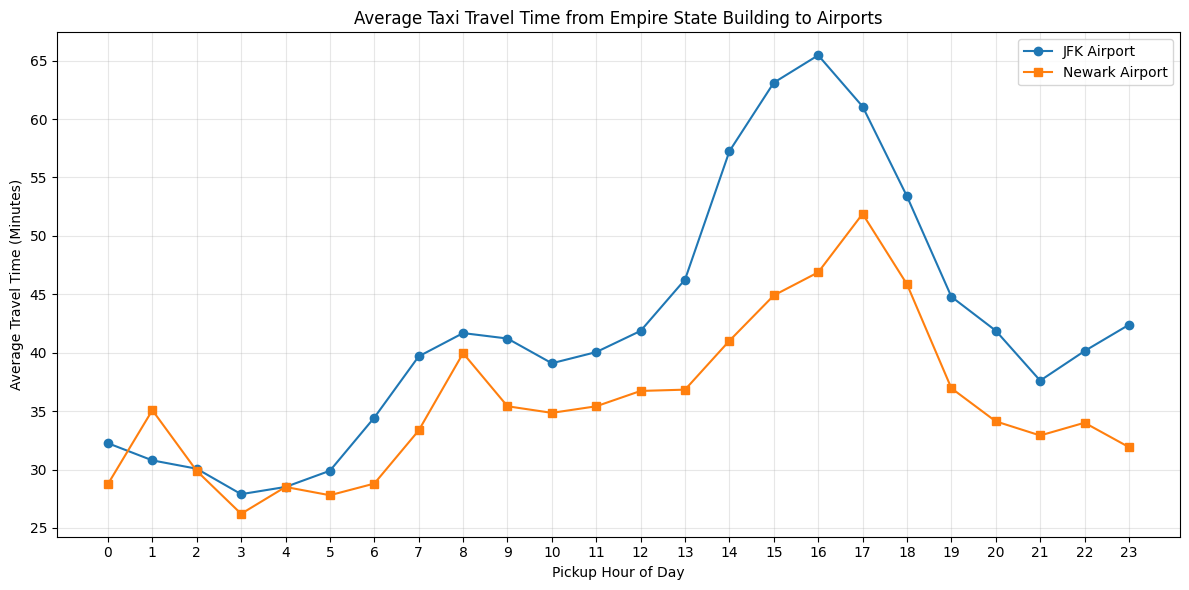

In [30]:
# The graph plot
plt.figure(figsize=(12, 6))

plt.plot(
    airport_comparison.index,
    airport_comparison["JFK (minutes)"],
    marker="o",
    label="JFK Airport"
)

plt.plot(
    airport_comparison.index,
    airport_comparison["Newark (minutes)"],
    marker="s",
    label="Newark Airport"
)

plt.title("Average Taxi Travel Time from Empire State Building to Airports")
plt.xlabel("Pickup Hour of Day")
plt.ylabel("Average Travel Time (Minutes)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Question 6
#### 6.1

In [31]:
SEED = 42

df_sample = df_clean.sample(
    n=20000,
    random_state=SEED
).copy()

print("Sample size:", len(df_sample))
print("Unique trips:", df_sample["id"].nunique())

from sklearn.preprocessing import StandardScaler

df_sample["pickup_hour"] = (
    pd.to_datetime(df_sample["pickup_datetime"]).dt.hour
)

# Cyclic hour encoding
df_sample["hour_sin"] = np.sin(
    2 * np.pi * df_sample["pickup_hour"] / 24
)

df_sample["hour_cos"] = np.cos(
    2 * np.pi * df_sample["pickup_hour"] / 24
)

feature_columns = [
    "pickup_latitude",
    "pickup_longitude",
    "dropoff_latitude",
    "dropoff_longitude",
    "trip_distance_km",
    "trip_duration",
    "average_speed_kmh",
    "passenger_count",
    "hour_sin",
    "hour_cos"
]

X = df_sample[feature_columns].copy()

# Check for missing values
print("Missing values:")
print(X.isna().sum())

# Standardise features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFeature matrix shape:", X_scaled.shape)

Sample size: 20000
Unique trips: 20000
Missing values:
pickup_latitude      0
pickup_longitude     0
dropoff_latitude     0
dropoff_longitude    0
trip_distance_km     0
trip_duration        0
average_speed_kmh    0
passenger_count      0
hour_sin             0
hour_cos             0
dtype: int64

Feature matrix shape: (20000, 10)


#### 6.2

,Component,Explained Variance (%),Cumulative Variance (%)
0,1,27.92,27.92
1,2,15.52,43.44
2,3,11.89,55.33
3,4,10.38,65.71
4,5,9.84,75.55
5,6,7.32,82.87
6,7,6.14,89.01
7,8,5.53,94.54
8,9,4.70,99.23
9,10,0.77,100.00


Components required for 90% variance: 8


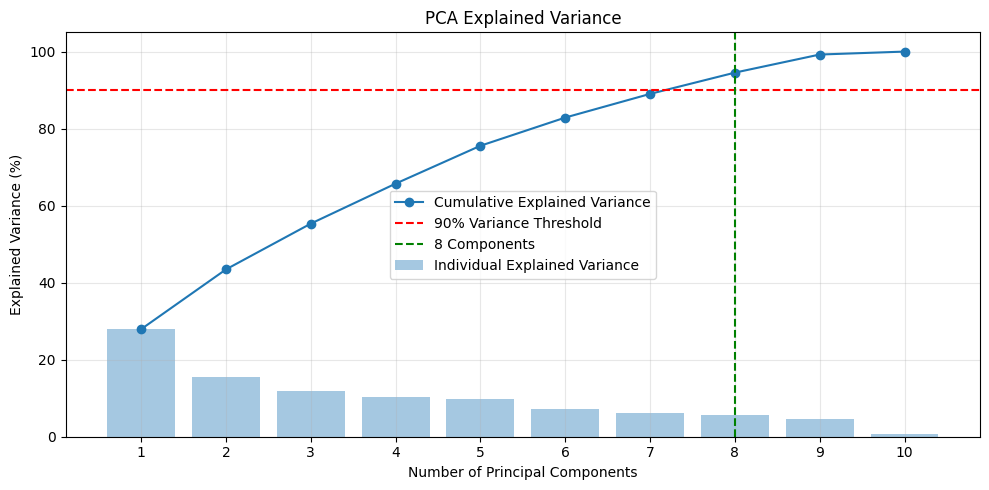

In [32]:

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Number of components explaining at least 90% variance
n_components_90 = np.searchsorted(cumulative_variance, 0.90) + 1

pca_results = pd.DataFrame({
    "Component": np.arange(1, len(explained_variance) + 1),
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(pca_results.round(2))

print("Components required for 90% variance:", n_components_90)


# The graph plot
plt.figure(figsize=(10, 5))

plt.plot(
    pca_results["Component"],
    pca_results["Cumulative Variance (%)"],
    marker="o",
    label="Cumulative Explained Variance"
)

plt.bar(
    pca_results["Component"],
    pca_results["Explained Variance (%)"],
    alpha=0.4,
    label="Individual Explained Variance"
)

plt.axhline(
    y=90,
    color="red",
    linestyle="--",
    label="90% Variance Threshold"
)

plt.axvline(
    x=n_components_90,
    color="green",
    linestyle="--",
    label=f"{n_components_90} Components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# PCA component coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_columns,
    columns=[
        f"PC{i+1}" for i in range(len(feature_columns))
    ]
)

# Display loadings for first three components
display(loadings.iloc[:, :3].round(3))

# Retain components explaining at least 90% variance
X_pca_90 = X_pca[:, :n_components_90]

print("Original shape:", X_scaled.shape)
print("PCA reduced shape:", X_pca_90.shape)
print(
    "Variance retained:",
    round(cumulative_variance[n_components_90 - 1] * 100, 2),
    "%"
)

,PC1,PC2,PC3
pickup_latitude,-0.230,0.570,0.027
pickup_longitude,0.420,0.181,-0.030
dropoff_latitude,-0.114,0.630,0.118
dropoff_longitude,0.272,0.408,0.131
trip_distance_km,0.568,-0.004,-0.025
trip_duration,0.414,-0.117,-0.181
average_speed_kmh,0.430,0.165,0.166
passenger_count,0.012,-0.020,0.092
hour_sin,0.033,0.099,-0.587
hour_cos,0.044,-0.170,0.743


Original shape: (20000, 10)
PCA reduced shape: (20000, 8)
Variance retained: 94.54 %


#### 6.3

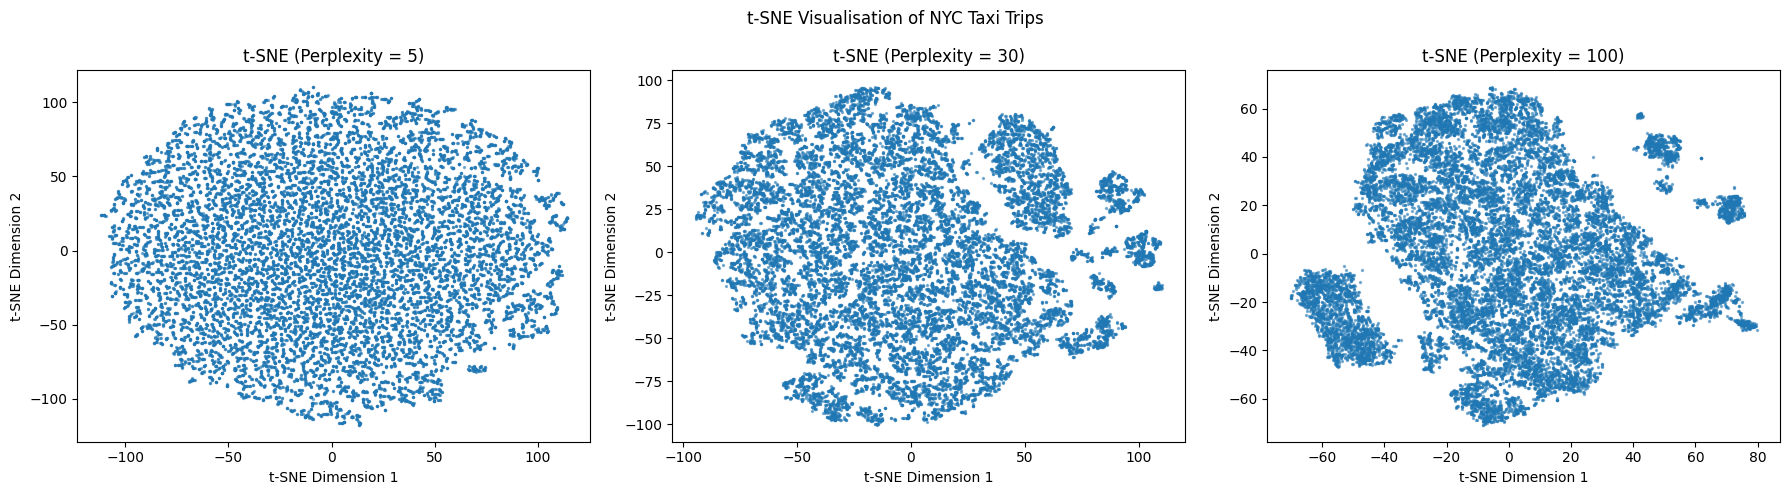

In [34]:
# T-SNE plot
perplexities = [5, 30, 100]

tsne_results = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, perplexity in zip(axes, perplexities):

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=SEED,
        init="pca",
        learning_rate="auto"
    )

    X_tsne = tsne.fit_transform(X_scaled)

    tsne_results[perplexity] = X_tsne

    ax.scatter(
        X_tsne[:, 0],
        X_tsne[:, 1],
        s=2,
        alpha=0.5
    )

    ax.set_title(f"t-SNE (Perplexity = {perplexity})")
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")

plt.suptitle("t-SNE Visualisation of NYC Taxi Trips")
plt.tight_layout()
plt.show()

#### 6.4

c:\Users\Wits student\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Wits student\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Wits student\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Wits student\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Wits student\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no 

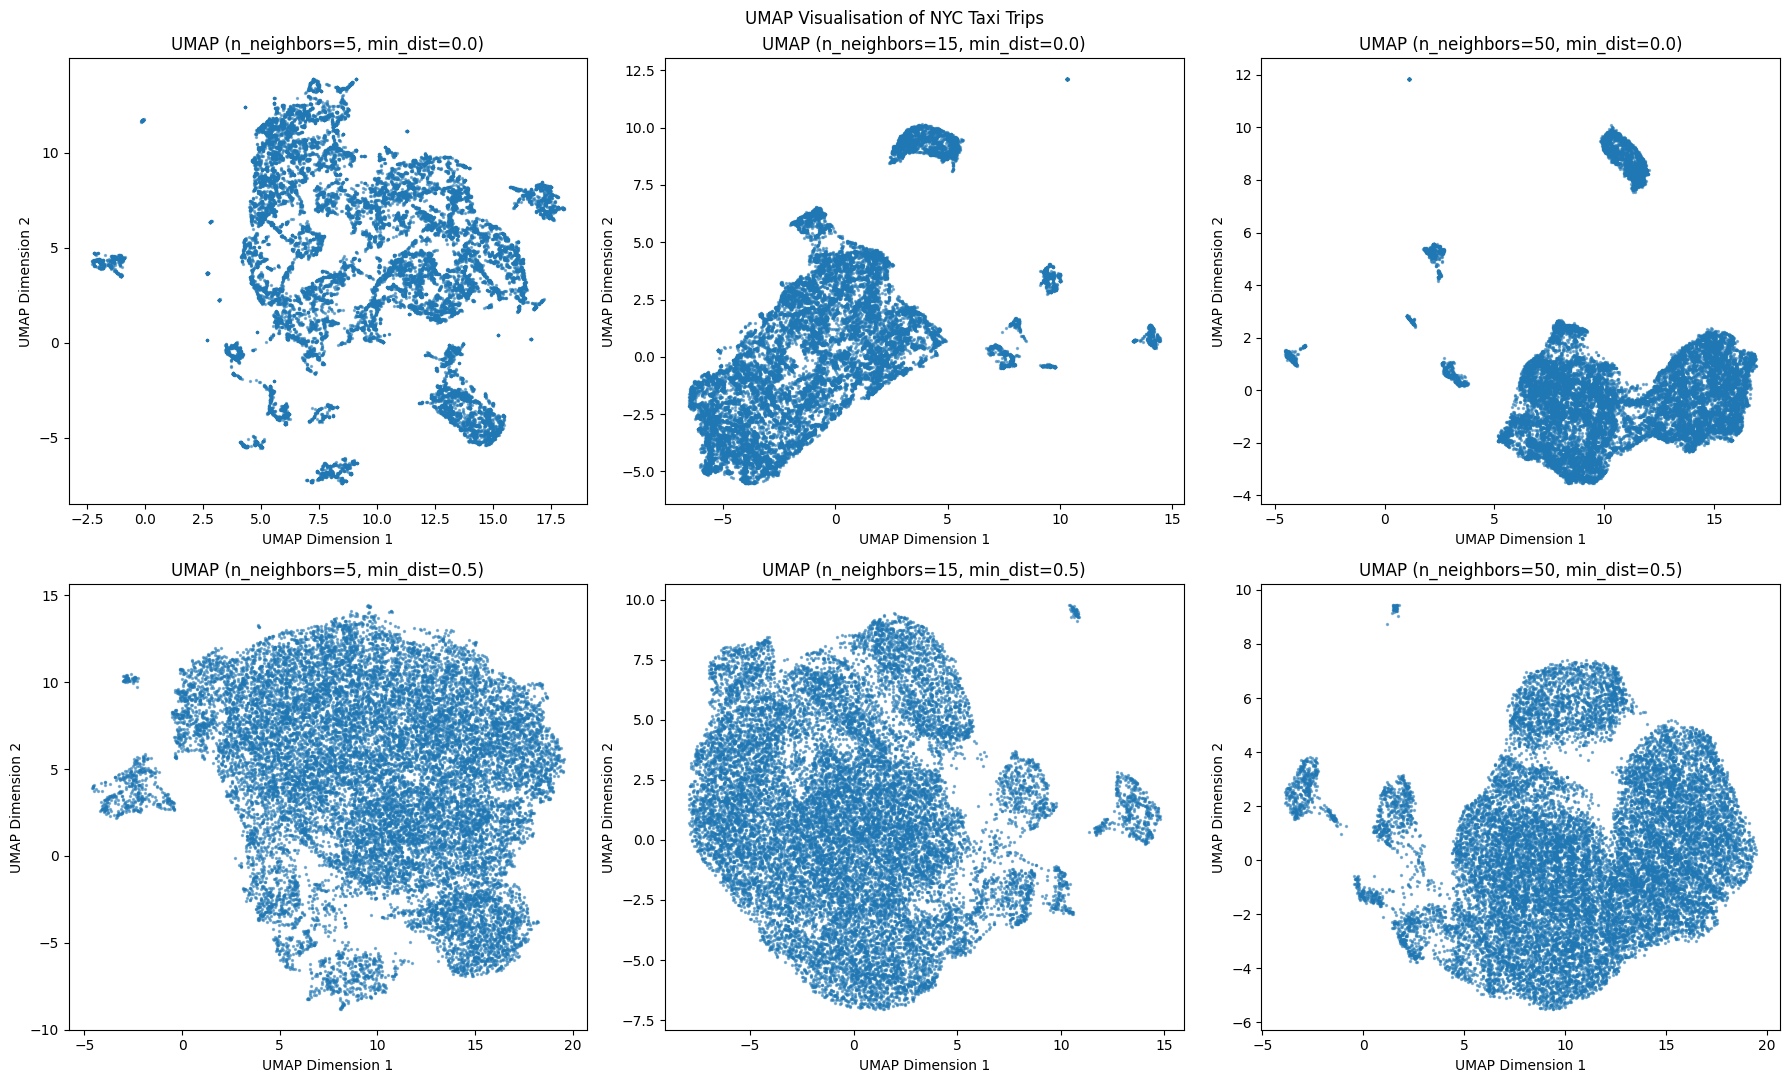

In [35]:
# UMAP plot

neighbors_values = [5, 15, 50]
min_dist_values = [0.0, 0.5]

umap_results = {}

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for row, min_dist in enumerate(min_dist_values):
    for col, n_neighbors in enumerate(neighbors_values):

        reducer = umap.UMAP(
            n_components=2,
            n_neighbors=n_neighbors,
            min_dist=min_dist,
            random_state=SEED
        )

        X_umap = reducer.fit_transform(X_scaled)

        umap_results[(n_neighbors, min_dist)] = X_umap

        ax = axes[row, col]

        ax.scatter(
            X_umap[:, 0],
            X_umap[:, 1],
            s=2,
            alpha=0.5
        )

        ax.set_title(
            f"UMAP (n_neighbors={n_neighbors}, min_dist={min_dist})"
        )

        ax.set_xlabel("UMAP Dimension 1")
        ax.set_ylabel("UMAP Dimension 2")

plt.suptitle("UMAP Visualisation of NYC Taxi Trips")
plt.tight_layout()
plt.show()

#### 6.5

In [36]:
# Clustering the Reduced Representations

representations = {
    "PCA (90% variance)": X_pca_90,
    "t-SNE (perplexity=100)": tsne_results[100],
    "UMAP (15, 0.0)": umap_results[(15, 0.0)]
}

cluster_results = {}
summary = []

for name, X_reduced in representations.items():

    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=100,
        min_samples=10
    )

    labels = clusterer.fit_predict(X_reduced)

    cluster_results[name] = labels

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)
    noise_pct = n_noise / len(labels) * 100

    summary.append({
        "Representation": name,
        "Number of Clusters": n_clusters,
        "Noise Points": n_noise,
        "Noise (%)": round(noise_pct, 2)
    })

cluster_summary = pd.DataFrame(summary)

display(cluster_summary)

,Representation,Number of Clusters,Noise Points,Noise (%)
0,PCA (90% variance),7,7008,35.04
1,t-SNE (perplexity=100),5,1,0.00
2,"UMAP (15, 0.0)",8,76,0.38


In [41]:
# Create cluster profiles for each representation

cluster_profiles = {}

for name, labels in cluster_results.items():

    profile_df = df_sample.copy()
    profile_df["cluster"] = labels

    profile_df["duration_minutes"] = (
        profile_df["trip_duration"] / 60
    )

    profile_df["day_type"] = np.where(
        profile_df["pickup_datetime"].dt.dayofweek < 5,
        "Weekday",
        "Weekend"
    )

    profile = (
        profile_df.groupby("cluster")
        .agg(
            trips=("cluster", "size"),
            median_distance_km=("trip_distance_km", "median"),
            median_duration_min=("duration_minutes", "median"),
            median_speed_kmh=("average_speed_kmh", "median"),
            median_pickup_hour=("pickup_hour", "median"),
            median_passengers=("passenger_count", "median"),
            weekday_pct=(
                "day_type",
                lambda x: (x == "Weekday").mean() * 100
            ),
            weekend_pct=(
                "day_type",
                lambda x: (x == "Weekend").mean() * 100
            )
        )
        .round(2)
    )

    cluster_profiles[name] = profile

    print(f"\n{name}")
    display(profile)



PCA (90% variance)


,trips,median_distance_km,median_duration_min,median_speed_kmh,median_pickup_hour,median_passengers,weekday_pct,weekend_pct
cluster,,,,,,,,
-1,7008,2.49,15.18,11.25,13.0,2.0,67.28,32.72
0,379,21.59,42.43,27.54,16.0,1.0,74.67,25.33
1,134,21.96,43.08,30.98,12.5,1.0,76.12,23.88
2,312,12.33,29.51,25.10,15.0,1.0,81.41,18.59
3,135,12.02,26.15,28.15,11.0,1.0,82.96,17.04
4,459,0.95,8.33,7.23,17.0,5.0,76.69,23.31
5,1187,1.10,8.35,8.18,17.0,2.0,70.68,29.32
6,10386,1.24,9.25,8.59,15.0,1.0,74.34,25.66



t-SNE (perplexity=100)


,trips,median_distance_km,median_duration_min,median_speed_kmh,median_pickup_hour,median_passengers,weekday_pct,weekend_pct
cluster,,,,,,,,
-1,1,4.19,15.07,16.67,5.0,1.0,100.00,0.00
0,433,21.19,41.00,27.54,15.0,1.0,74.60,25.40
1,577,12.10,28.47,24.37,15.0,1.0,76.60,23.40
2,170,21.92,41.08,30.98,12.5,1.0,74.71,25.29
3,1934,1.39,10.43,8.74,14.0,5.0,70.22,29.78
4,16885,1.48,10.55,9.24,14.0,1.0,71.82,28.18



UMAP (15, 0.0)


,trips,median_distance_km,median_duration_min,median_speed_kmh,median_pickup_hour,median_passengers,weekday_pct,weekend_pct
cluster,,,,,,,,
-1,76,20.13,31.95,34.91,13.0,1.0,72.37,27.63
0,470,12.14,29.35,24.63,15.0,1.0,78.30,21.70
1,1934,1.38,10.38,8.74,14.0,5.0,70.22,29.78
2,429,21.19,41.00,27.54,15.0,1.0,74.36,25.64
3,16379,1.44,10.37,9.05,14.0,1.0,71.81,28.19
4,157,21.98,43.27,30.89,13.0,1.0,75.80,24.20
5,123,1.73,8.77,14.78,9.0,1.0,61.79,38.21
6,130,7.21,19.44,22.81,4.0,1.0,66.15,33.85
7,302,12.44,26.20,29.03,11.0,1.0,77.81,22.19


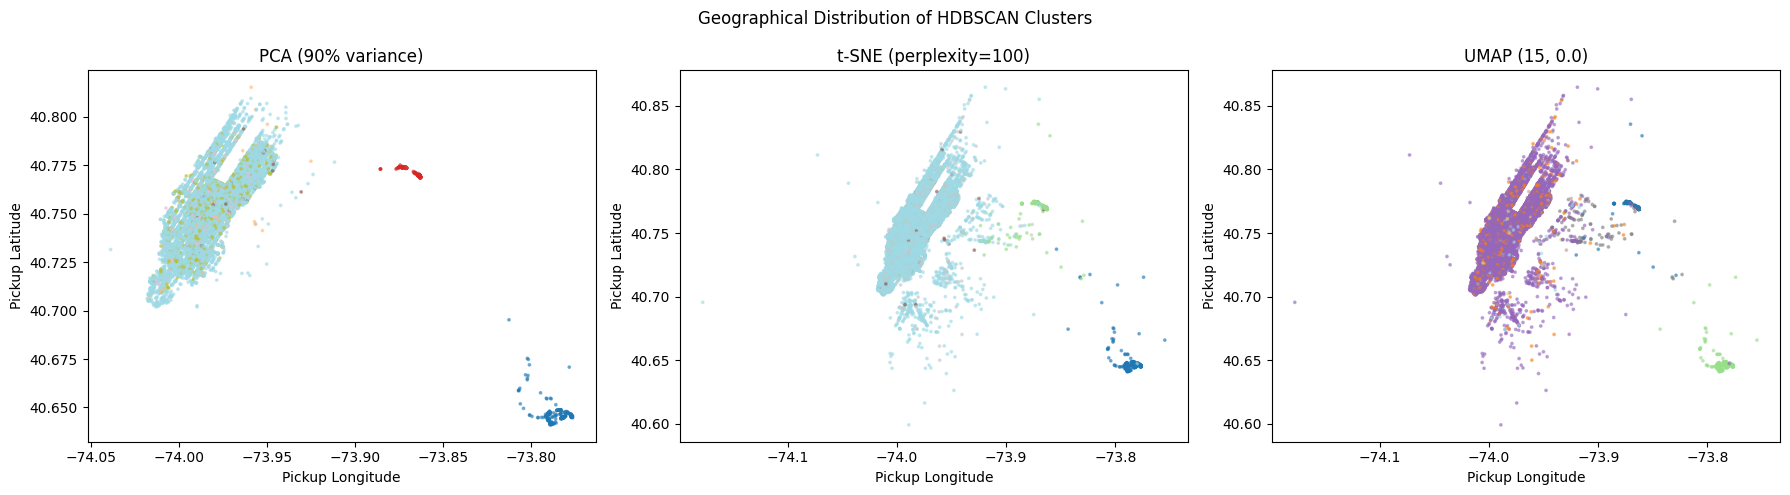

In [38]:
# Geographical Cluster Visualisation

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, labels) in zip(axes, cluster_results.items()):

    # Focus the map on the main NYC region
    mask = (
        df_sample["pickup_latitude"].between(40.5, 41.0) &
        df_sample["pickup_longitude"].between(-74.3, -73.6)
    )

    # Exclude noise from coloured clusters
    mask = mask & (labels != -1)

    scatter = ax.scatter(
        df_sample.loc[mask, "pickup_longitude"],
        df_sample.loc[mask, "pickup_latitude"],
        c=np.asarray(labels)[mask.to_numpy()],
        cmap="tab20",
        s=3,
        alpha=0.5
    )

    ax.set_title(name)
    ax.set_xlabel("Pickup Longitude")
    ax.set_ylabel("Pickup Latitude")

plt.suptitle("Geographical Distribution of HDBSCAN Clusters")
plt.tight_layout()
plt.show()

#### 6.6

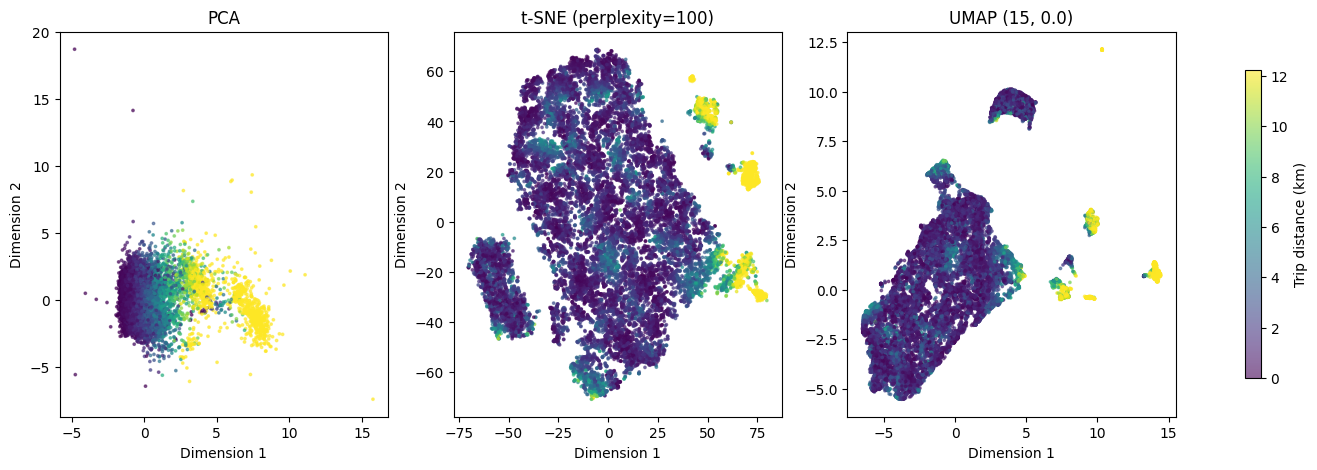

In [42]:
# Compare best embeddings using the same trip-distance colouring

embeddings = {
    "PCA": X_pca_90[:, :2],
    "t-SNE (perplexity=100)": tsne_results[100],
    "UMAP (15, 0.0)": umap_results[(15, 0.0)]
}

distance = df_sample["trip_distance_km"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, embedding) in zip(axes, embeddings.items()):

    scatter = ax.scatter(
        embedding[:, 0],
        embedding[:, 1],
        c=distance,
        cmap="viridis",
        vmin=0,
        vmax=np.percentile(distance, 95),
        s=3,
        alpha=0.6
    )

    ax.set_title(name)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

fig.colorbar(
    scatter,
    ax=axes,
    label="Trip distance (km)",
    shrink=0.8
)

plt.show()

In [43]:
# Question 6.6: Runtime comparison

import time
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

runtime_results = []

methods = {
    "PCA": lambda: PCA(
        n_components=8,
        random_state=42
    ).fit_transform(X_scaled),

    "t-SNE": lambda: TSNE(
        n_components=2,
        perplexity=100,
        random_state=42,
        init="pca",
        learning_rate="auto"
    ).fit_transform(X_scaled),

    "UMAP": lambda: umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.0,
        random_state=42
    ).fit_transform(X_scaled)
}

for name, method in methods.items():

    start = time.perf_counter()

    method()

    elapsed = time.perf_counter() - start

    runtime_results.append({
        "Method": name,
        "Runtime (seconds)": round(elapsed, 2)
    })

display(pd.DataFrame(runtime_results))

c:\Users\Wits student\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,Method,Runtime (seconds)
0,PCA,0.12
1,t-SNE,561.43
2,UMAP,25.77


In [39]:
# Adjusted Rand Index (ARI)

from sklearn.metrics import adjusted_rand_score


names = list(cluster_results.keys())

ari_matrix = pd.DataFrame(
    index=names,
    columns=names,
    dtype=float
)

for name1 in names:
    for name2 in names:
        ari_matrix.loc[name1, name2] = adjusted_rand_score(
            cluster_results[name1],
            cluster_results[name2]
        )

display(ari_matrix.round(3))

,PCA (90% variance),t-SNE (perplexity=100),"UMAP (15, 0.0)"
PCA (90% variance),1.000,0.219,0.250
t-SNE (perplexity=100),0.219,1.000,0.892
"UMAP (15, 0.0)",0.250,0.892,1.000


In [45]:
# Question 6.6: Identify airport trips
airports = {
    "JFK": (40.647929, -73.777813),
    "Newark": (40.689442, -74.173242)
}


df_sample["airport_destination"] = "Other"

for airport, (lat, lon) in airports.items():

    distance = haversine_np(
        df_sample["dropoff_latitude"],
        df_sample["dropoff_longitude"],
        lat,
        lon
    )

    df_sample.loc[
        distance <= 2,
        "airport_destination"
    ] = airport

display(df_sample["airport_destination"].value_counts())

airport_destination
Other     19797
JFK         159
Newark       44
Name: count, dtype: int64

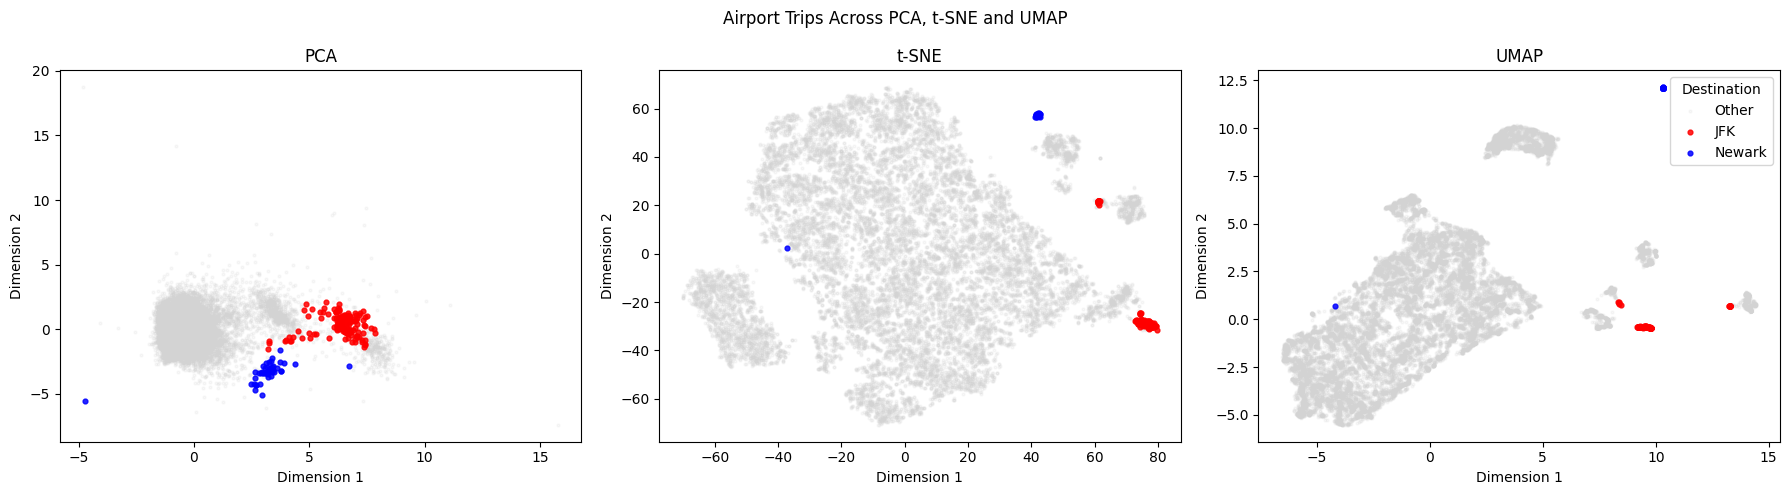

In [47]:
# Question 6.6: Airport trips across embeddings

embeddings = {
    "PCA": X_pca_90[:, :2],
    "t-SNE": tsne_results[100],
    "UMAP": umap_results[(15, 0.0)]
}

airport_labels = df_sample["airport_destination"].to_numpy()

colors = {
    "Other": "lightgrey",
    "JFK": "red",
    "Newark": "blue"
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, embedding) in zip(
    axes, embeddings.items()
):

    for category in ["Other", "JFK", "Newark"]:

        mask = airport_labels == category

        ax.scatter(
            embedding[mask, 0],
            embedding[mask, 1],
            c=colors[category],
            s=4 if category == "Other" else 12,
            alpha=0.15 if category == "Other" else 0.85,
            label=category
        )

    ax.set_title(name)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

axes[-1].legend(title="Destination")

plt.suptitle(
    "Airport Trips Across PCA, t-SNE and UMAP"
)

plt.tight_layout()
plt.show()

In [48]:
# Question 6.6: Airport composition of clusters

for name, labels in cluster_results.items():

    comparison = pd.DataFrame({
        "cluster": labels,
        "airport": df_sample["airport_destination"].to_numpy()
    })

    counts = pd.crosstab(
        comparison["cluster"],
        comparison["airport"]
    )

    percentages = pd.crosstab(
        comparison["cluster"],
        comparison["airport"],
        normalize="index"
    ) * 100

    print(f"\n{name} - Airport trip counts")
    display(counts)

    print(f"{name} - Airport percentages per cluster")
    display(percentages.round(2))


PCA (90% variance) - Airport trip counts


airport,JFK,Newark,Other
cluster,,,
-1,24,44,6940
0,12,0,367
1,123,0,11
2,0,0,312
3,0,0,135
4,0,0,459
5,0,0,1187
6,0,0,10386


PCA (90% variance) - Airport percentages per cluster


airport,JFK,Newark,Other
cluster,,,
-1,0.34,0.63,99.03
0,3.17,0.00,96.83
1,91.79,0.00,8.21
2,0.00,0.00,100.00
3,0.00,0.00,100.00
4,0.00,0.00,100.00
5,0.00,0.00,100.00
6,0.00,0.00,100.00



t-SNE (perplexity=100) - Airport trip counts


airport,JFK,Newark,Other
cluster,,,
-1,0,0,1
0,16,0,417
1,0,43,534
2,143,0,27
3,0,0,1934
4,0,1,16884


... (2 outputs left out)


UMAP (15, 0.0) - Airport trip counts


airport,JFK,Newark,Other
cluster,,,
-1,0,43,33
0,0,0,470
1,0,0,1934
2,16,0,413
3,0,1,16378
4,138,0,19
5,5,0,118
6,0,0,130
7,0,0,302


UMAP (15, 0.0) - Airport percentages per cluster


airport,JFK,Newark,Other
cluster,,,
-1,0.00,56.58,43.42
0,0.00,0.00,100.00
1,0.00,0.00,100.00
2,3.73,0.00,96.27
3,0.00,0.01,99.99
4,87.90,0.00,12.10
5,4.07,0.00,95.93
6,0.00,0.00,100.00
7,0.00,0.00,100.00
